# Beach safety — modelling
Fits the two models planned in `beach_features.ipynb`, checks them on held-out seasons, combines them into **expected severe incidents**, and prices each funding lever per beach so the allocation step only needs unit costs.

| Model | Unit | Target | Form | Levers it carries |
|---|---|---|---|---|
| Frequency | beach-month | `n_people` | Negative binomial, offset `log_visitors`, beach + month fixed effects | campaigns (lifeguards, drones tested: no effect) |
| Severity | person | `sev` | Bayesian logistic, beach effects pooled within region | lifeguard on duty (via `coverage_hat`), drone hours |
| Combined | beach-month | expected severe | $E[\text{people}] \times E[\Pr(\text{severe})]$ | all three |

Validation is out-of-time throughout: fit on seasons to 2023–24 (`train`), score on 2024–25 and 2025–26 (`test`), then refit on all ten seasons for the allocation.

All model code is in `beach_models.py` (written by the next cell), next to `beach_features.py`. The allocation notebook imports both and calls `expected_severe()` on counterfactual panels.

In [1]:
%%writefile beach_models.py
"""Frequency, severity and combined expected-severe models for the beach-safety case.

Builds on beach_features.py. Everything a funding scenario needs is a pure function of
(raw panel with changed levers) + fitted objects, so the allocation notebook can call
expected_severe() on counterfactual inputs and get the same transforms used in fitting.
"""
import numpy as np
import pandas as pd
import patsy
import statsmodels.formula.api as smf
from scipy.special import expit

import beach_features as bf

# ---------------------------------------------------------------- extra model terms
def region_of(pc):
    if pc < 2250:
        return "Sydney"
    if pc < 2400:
        return "Central Coast & Hunter"
    if pc < 2500:
        return "North Coast"
    if pc <= 2535:
        return "Illawarra"
    return "South Coast"


SCALE_COLS = ['t_years', 'swell_max_m', 'water_temp', 'rain_mm', 'wind_days', 'tourist_ratio', 'surfer_prop', 'n_rips',
              'log_shore_len', 'log_visitor_density', 'coverage_hat', 'drone_dose', 'campaign_idx',
              'log1p_lg_hrs', 'lg_hrs_cap', 'equip_rating', 'first_aid_cap']   # same list as beach_features.ipynb
COVERAGE_FORMULA = "on_duty ~ np.log1p(lg_hrs) + C(mo)"                    # same spec as beach_features.ipynb


def fit_coverage(Q_raw, test_from_fy=2025):
    """Refit the first-stage coverage model exactly as in beach_features.ipynb (train seasons, lg_hrs > 0)."""
    Q = Q_raw.copy()
    d = pd.to_datetime(Q.month, format="%m/%Y")
    Q["mo"] = d.dt.month
    Q["fy"] = d.dt.year + (Q.mo >= 9)
    return smf.logit(COVERAGE_FORMULA, Q[(Q.lg_hrs > 0) & (Q.fy < test_from_fy)]).fit(disp=0)


DRONE_MAX = 150.0   # drone hrs/month: observed maximum; dose effects beyond this are extrapolation
CAMPAIGN_MONTHS = {11, 12, 1, 2}   # campaigns are only ever observed Nov-Feb


def add_model_terms(df, postcodes):
    """Terms chosen in model selection (see notebook sections 2 and 3).

    campaign_sqrt : sqrt(campaign_idx); concave dose-response (beat on/off, linear and binned forms).
    drone_dose_z  : drone hrs/100, train-scaled (from beach_features); linear on the log-odds scale. Chosen over
                    on/off and log(1+hrs) because ~10 h/month (winter) shows no benefit at all.
    region        : 5 coastal regions from postcode (severity random-effect level).
    """
    df = df.copy()
    df["campaign_sqrt"] = np.sqrt(df.campaign_idx)
    df["region"] = df.beach_nm.map(postcodes).map(region_of)
    if "on_duty" in df:
        df["onduty_x_swell"] = df.on_duty * (df.swell_max_m - bf.SWELL_CENTRE)
    return df


def support_check(P_scn):
    """Lever values outside what the data have ever shown. The models will still predict there,
    but the answer is an assumption, not an estimate."""
    mo = pd.to_datetime(P_scn.month, format="%m/%Y").dt.month
    return pd.DataFrame({
        "drone_hrs_above_max": P_scn.drone_hrs > DRONE_MAX,
        "winter_drone_above_15h": mo.isin(bf.WINTER) & (P_scn.drone_hrs > 15),
        "campaign_outside_nov_feb": ~mo.isin(CAMPAIGN_MONTHS) & (P_scn.campaign_idx > 0),
        "lg_hrs_above_3500": P_scn.lg_hrs > 3500,
    }).sum()


# ---------------------------------------------------------------- frequency model
ENV = ["swell_max_m_z", "water_temp_z", "rain_mm_z", "wind_days_z", "tourist_ratio_z", "surfer_prop_z"]
FREQ_LEVERS = ["coverage_hat_z", "drone_dose_z", "campaign_sqrt"]
FREQ_FORMULA = "n_people ~ C(beach_nm) + C(mo) + t_years_z + " + " + ".join(ENV + FREQ_LEVERS)


def fit_frequency(d, formula=FREQ_FORMULA):
    """Negative binomial (NB2), log(visitors) offset, beach and month-of-year fixed effects."""
    mod = smf.negativebinomial(formula, d, offset=d.log_visitors)
    r = mod.fit(disp=0, maxiter=500, method="bfgs")
    return mod.fit(start_params=r.params, disp=0, maxiter=200, method="newton")


def freq_design(res, F):
    data = res.model.data
    di = getattr(data, "design_info", None) or getattr(data, "model_spec")   # statsmodels <0.15 / >=0.15
    return np.asarray(patsy.build_design_matrices([di], F, return_type="matrix")[0])


def freq_param_draws(res, n, seed=0):
    """Draws of the mean-model coefficients from their asymptotic normal (alpha not needed for the mean)."""
    names = [p for p in res.params.index if p != "alpha"]
    mu = res.params[names].values
    cov = res.cov_params().loc[names, names].values
    rng = np.random.default_rng(seed)
    return rng.multivariate_normal(mu, cov, size=n, method="eigh")


def predict_people(res, F, draws=None):
    """Expected people involved per beach-month. Returns (rows,) for point estimate or (S, rows) for draws."""
    X = freq_design(res, F)
    off = F.log_visitors.values
    if draws is None:
        beta = res.params.drop("alpha").values
        return np.exp(X @ beta + off)
    return np.exp(draws @ X.T + off)


# ---------------------------------------------------------------- severity model
PERSON_X = ["age_0_17", "age_55p", "male", "swim_beginner", "swim_intermediate", "non_local", "alone"]
ROW_X = ["drone_dose_z", "swell_max_m_z", "winter", "rocky", "n_rips_z", "first_aid_cap_z", "tourist_ratio_z"]
SEV_X = PERSON_X + ["on_duty", "onduty_x_swell"] + ROW_X


def build_severity_model(d, beaches, regions, beach_region):
    """Hierarchical logistic: weakly informative N(0,1) on (mostly standardised/binary) log-odds,
    beach effects partially pooled toward their region."""
    import pymc as pm
    bidx = d.beach_nm.map({b: i for i, b in enumerate(beaches)}).values
    with pm.Model(coords={"x": SEV_X, "beach": beaches, "region": regions}) as m:
        X = pm.Data("X", d[SEV_X].values.astype(float))
        b = pm.Data("b", bidx)
        a = pm.Normal("a", -5, 2)
        beta = pm.Normal("beta", 0, 1, dims="x")
        s_r = pm.HalfNormal("s_region", 0.5)
        z_r = pm.Normal("z_r", 0, 1, dims="region")
        s_b = pm.HalfNormal("s_beach", 0.5)
        z_b = pm.Normal("z_b", 0, 1, dims="beach")
        u = pm.Deterministic("u_beach", s_r * z_r[beach_region] + s_b * z_b, dims="beach")
        pm.Bernoulli("y", logit_p=a + pm.math.dot(X, beta) + u[b], observed=d.sev.values)
    return m


def posterior_arrays(idata, n=None, seed=0):
    """Flatten chains -> dict of numpy arrays, optionally thinned to n draws."""
    post = idata.posterior
    post = post.to_dataset() if hasattr(post, "to_dataset") else post   # PyMC >= 6 returns a DataTree
    post = post.stack(s=("chain", "draw"))
    out = {"a": post["a"].values,
           "beta": post["beta"].transpose("s", "x").values,
           "u": post["u_beach"].transpose("s", "beach").values,
           "x": list(post["x"].values), "beaches": list(post["beach"].values)}
    if n is not None and n < len(out["a"]):
        idx = np.random.default_rng(seed).choice(len(out["a"]), n, replace=False)
        for k in ["a", "beta", "u"]:
            out[k] = out[k][idx]
    return out


def save_posterior(post, path):
    np.savez(path, a=post["a"], beta=post["beta"], u=post["u"], x=np.array(post["x"]), beaches=np.array(post["beaches"]))


def load_posterior(path):
    z = np.load(path, allow_pickle=False)
    return {"a": z["a"], "beta": z["beta"], "u": z["u"], "x": [str(v) for v in z["x"]], "beaches": [str(v) for v in z["beaches"]]}


def sev_prob(post, d):
    """P(severe) for observed person rows, (S, N)."""
    bi = d.beach_nm.map({b: i for i, b in enumerate(post["beaches"])}).values
    eta = post["a"][:, None] + post["beta"] @ d[post["x"]].values.T.astype(float) + post["u"][:, bi]
    return expit(eta)


# ---------------------------------------------------------------- combining: expected severe
def person_templates(G, postcodes, min_n=40):
    """Who turns up in an incident, by beach x season. Thin cells fall back to region x season."""
    G = G.copy()
    G["region"] = G.beach_nm.map(postcodes).map(region_of)
    T = {}
    for (b, w), g in G.groupby(["beach_nm", "winter"]):
        T[(b, w)] = g[PERSON_X].values.astype(float)
    R = {(r, w): g[PERSON_X].values.astype(float) for (r, w), g in G.groupby(["region", "winter"])}
    beach_region = G.drop_duplicates("beach_nm").set_index("beach_nm").region
    out = {}
    for b in beach_region.index:
        for w in (0, 1):
            t = T.get((b, w))
            out[(b, w)] = t if t is not None and len(t) >= min_n else R[(beach_region[b], w)]
    return out


def expected_sev_share(post, F, templates):
    """E[P(severe) | beach-month] for each row of F, (S, rows).

    Averages over the beach's person template, and over lifeguard presence using coverage_hat:
      P = c * p(on duty) + (1 - c) * p(off duty).
    """
    x = post["x"]
    B = post["beta"]
    jP = [x.index(c) for c in PERSON_X]
    jR = [x.index(c) for c in ROW_X]
    j_on, j_int = x.index("on_duty"), x.index("onduty_x_swell")
    bmap = {b: i for i, b in enumerate(post["beaches"])}
    S = len(post["a"])
    out = np.empty((S, len(F)))
    F = F.reset_index(drop=True)
    for (b, w), rows in F.groupby(["beach_nm", "winter"]).groups.items():
        rows = np.asarray(rows)
        pe = B[:, jP] @ templates[(b, w)].T                              # (S, n_t)
        base = post["a"] + post["u"][:, bmap[b]]                          # (S,)
        sub = F.loc[rows]
        re = B[:, jR] @ sub[ROW_X].values.T.astype(float)                 # (S, r)
        lift = B[:, [j_on]] + B[:, [j_int]] * (sub.swell_max_m.values - bf.SWELL_CENTRE)   # (S, r)
        c = sub.coverage_hat.values
        eta0 = (base[:, None] + re)[:, :, None] + pe[:, None, :]           # (S, r, n_t)
        p0 = expit(eta0).mean(2)
        p1 = expit(eta0 + lift[:, :, None]).mean(2)
        out[:, rows] = c * p1 + (1 - c) * p0
    return out


def expected_severe(F, freq_res, freq_draws, post, templates):
    """Expected severe people per beach-month, (S, rows). Pairs frequency draw s with severity draw s."""
    S = min(len(freq_draws), len(post["a"]))
    people = predict_people(freq_res, F, freq_draws[:S])
    post_s = {k: (v[:S] if k in ("a", "beta", "u") else v) for k, v in post.items()}
    return people * expected_sev_share(post_s, F, templates)


def scenario_features(P_scn, cov_model, scaler, postcodes):
    """Raw (counterfactual) panel -> model-ready beach-month features, through the fitted transforms."""
    F = bf.apply_scaler(bf.panel_features(P_scn, cov_model), scaler)
    return add_model_terms(F, postcodes)

Overwriting beach_models.py


## 0. Setup
Rebuilds the feature tables from the raw files through `beach_features`, so this notebook needs only the two CSVs and the two `.py` files.

In [2]:
import importlib, json, os, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import roc_auc_score
import pymc as pm, arviz as az
import beach_features as bf, beach_models as bm
importlib.reload(bf); importlib.reload(bm)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
BLUE, ORANGE, GREY, RED = '#2a6f97', '#e07a2f', '#9aa5b1', '#c0392b'

DATA = './'                      # folder holding panel.csv and person.csv: adjust to yours
OUT = 'models/'; os.makedirs(OUT, exist_ok=True)
SAMPLE_KW = dict(draws=1000, tune=1000, chains=4, target_accept=0.9, progressbar=False)
N_DRAWS = 1000                   # posterior draws carried into the combined model

P_raw = pd.read_csv(DATA + 'panel.csv'); Q_raw = pd.read_csv(DATA + 'person.csv')
POSTCODES = P_raw.drop_duplicates('beach_nm').set_index('beach_nm').postcode

def build_tables(cov_model):
    F = bf.panel_features(P_raw, cov_model)
    G = bf.person_features(Q_raw, F)
    return F, G

cov_tr = bm.fit_coverage(Q_raw)                         # train seasons only, as in beach_features.ipynb
F, G = build_tables(cov_tr)
SCALER = bf.fit_scaler(F, bm.SCALE_COLS)
F = bm.add_model_terms(bf.apply_scaler(F, SCALER), POSTCODES)
G = bm.add_model_terms(bf.apply_scaler(G, SCALER), POSTCODES)
tr, te = F[F.split == 'train'].reset_index(drop=True), F[F.split == 'test'].reset_index(drop=True)
Gtr, Gte = G[G.split == 'train'], G[G.split == 'test']

# same features as the saved feature tables, if they are around
if os.path.exists('features/panel_features.csv'):
    saved = pd.read_csv('features/panel_features.csv')
    assert np.allclose(saved.coverage_hat_z, F.coverage_hat_z), 'features differ from features/panel_features.csv'
print(f'panel {F.shape}, person {G.shape}; severe: train {Gtr.sev.sum()}, test {Gte.sev.sum()}')

panel (9600, 60), person (33941, 81); severe: train 176, test 44


## 1. Frequency model
**Question:** how many people are involved in incidents at a beach in a month, given exposure, conditions and the levers?

Negative binomial (NB2) with `log(visitors)` as offset (the EDA found a within-beach elasticity of 1.03) and month-of-year effects.

The main design choice is **beach fixed effects versus static beach attributes**. Lifeguard hours and drones are deployed where beaches are busy and well run, so a model that compares *across* beaches credits the levers with that difference. Fixed effects keep only *within-beach* variation for the levers. With 120 months per beach, the incidental-parameter cost is negligible. The static attributes (rips, rocky, …) drop out, but they are not levers, so allocation does not need them.

In [3]:
def nb_logscore(res, d):
    mu = bm.predict_people(res, d); r = 1 / res.params['alpha']
    return stats.nbinom.logpmf(d.n_people, r, r / (r + mu)).sum()

env = ' + '.join(bm.ENV)
static = 'n_rips_z + rocky + fishing + rockpool + log_shore_len_z'
fe = f'n_people ~ C(beach_nm) + C(mo) + t_years_z + {env}'
specs = {
    'A  static attributes, no beach FE': f'n_people ~ C(mo) + t_years_z + {env} + {static} + coverage_hat_z + drone_on + campaign_on',
    'B  beach FE, levers on/off':        f'{fe} + coverage_hat_z + drone_on + campaign_on',
    'C  B, campaign linear':             f'{fe} + coverage_hat_z + drone_on + campaign_idx_z',
    'D  B, campaign sqrt (final form)':  f'{fe} + coverage_hat_z + drone_on + campaign_sqrt',
    'E  D, drone dose (final)':          bm.FREQ_FORMULA,
    'F  E, lifeguards log1p(hrs)':       bm.FREQ_FORMULA.replace('coverage_hat_z', 'log1p_lg_hrs_z'),
    'G  E + infrastructure':             bm.FREQ_FORMULA + ' + first_aid_cap_z + equip_rating_z + flags + pa_system + marine_health_low',
}
rows, fits = [], {}
for k, f in specs.items():
    r = bm.fit_frequency(tr, f); fits[k] = r
    irr = lambda p: np.exp(r.params[p]) if p in r.params else np.nan
    lg = 'coverage_hat_z' if 'coverage_hat_z' in r.params else 'log1p_lg_hrs_z'
    dr = 'drone_on' if 'drone_on' in r.params else 'drone_dose_z'
    cp = [p for p in ['campaign_on', 'campaign_idx_z', 'campaign_sqrt'] if p in r.params][0]
    rows.append({'spec': k, 'AIC': r.aic, 'test log score': nb_logscore(r, te),
                 'IRR lifeguard': irr(lg), 'IRR drone': irr(dr), 'IRR campaign': irr(cp), 'alpha': r.params['alpha']})
spec_tab = pd.DataFrame(rows).set_index('spec')
spec_tab.round(3)

,AIC,test log score,IRR lifeguard,IRR drone,IRR campaign,alpha
spec,,,,,,
"A static attributes, no beach FE",25629.987,-3452.046,0.852,1.102,0.560,0.315
"B beach FE, levers on/off",25186.527,-3385.249,0.972,1.006,0.584,0.244
"C B, campaign linear",25162.699,-3389.083,0.978,1.004,0.809,0.241
"D B, campaign sqrt (final form)",25144.955,-3384.161,0.973,1.004,0.475,0.238
"E D, drone dose (final)",25144.152,-3383.312,0.973,0.989,0.475,0.238
"F E, lifeguards log1p(hrs)",25145.067,-3383.661,1.003,0.989,0.476,0.238
G E + infrastructure,25151.280,-3385.837,0.973,0.988,0.475,0.238


**Reading the table**
- **Beach fixed effects win clearly out of sample.** The test log score improves by about 65 nats from A to B.
- The cross-beach model (A) credits lifeguards with a 15%-per-SD reduction and drones with a 10% *increase*. Both disappear within beach (IRR ≈ 1.0). Those "effects" were differences between beaches, not effects of the levers.
- **Campaigns are the one frequency lever that survives,** at about −42% when active, and the effect is concave in intensity. The square-root form has the best AIC and a binned check (not shown) confirms diminishing returns: IRR 0.71, 0.58, 0.54, 0.51 across four intensity bands.
- Infrastructure terms (first aid, equipment, flags, PA, marine health) add nothing to frequency.
- The final model is **E**. Lifeguard and drone terms stay in at their (near-zero) estimates, so the allocation carries their uncertainty instead of assuming a zero effect.

alpha = 0.238  (Var = mu + alpha*mu^2)


,IRR,lo95,hi95,p
t_years_z,1.000,0.979,1.022,0.974
swell_max_m_z,1.034,0.997,1.073,0.071
water_temp_z,1.003,0.940,1.069,0.939
rain_mm_z,1.021,0.996,1.046,0.095
wind_days_z,1.022,0.998,1.046,0.073
tourist_ratio_z,1.189,1.145,1.235,0.000
surfer_prop_z,0.969,0.891,1.053,0.461
coverage_hat_z,0.973,0.921,1.029,0.336
drone_dose_z,0.989,0.965,1.013,0.368
campaign_sqrt,0.475,0.430,0.525,0.000


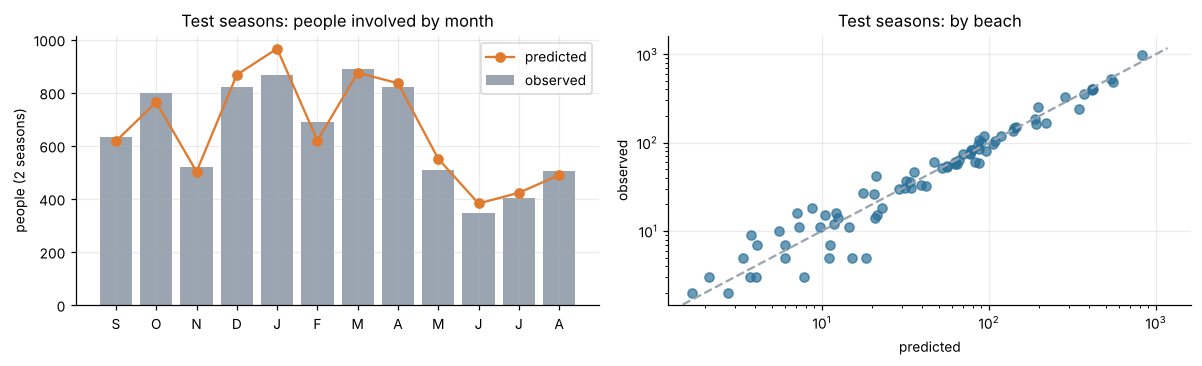

test total: predicted 7,890 vs observed 7,802; beach-level correlation (log) 0.968


In [4]:
freq_tr = fits['E  D, drone dose (final)']
keep = [p for p in freq_tr.params.index if not p.startswith('C(') and p not in ('Intercept', 'alpha')]
ci = freq_tr.conf_int().loc[keep]
freq_irr = pd.DataFrame({'IRR': np.exp(freq_tr.params[keep]), 'lo95': np.exp(ci[0]), 'hi95': np.exp(ci[1]), 'p': freq_tr.pvalues[keep]})
print(f"alpha = {freq_tr.params['alpha']:.3f}  (Var = mu + alpha*mu^2)")
display(freq_irr.round(3))

te_f = te.assign(pred=bm.predict_people(freq_tr, te))
by_mo = te_f.groupby('mo')[['n_people', 'pred']].sum().reindex([9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8])
by_b = te_f.groupby('beach_nm')[['n_people', 'pred']].sum()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(range(12), by_mo.n_people, color=GREY, label='observed'); ax[0].plot(range(12), by_mo.pred, 'o-', color=ORANGE, label='predicted')
ax[0].set_xticks(range(12), ['S', 'O', 'N', 'D', 'J', 'F', 'M', 'A', 'M', 'J', 'J', 'A'])
ax[0].set(title='Test seasons: people involved by month', ylabel='people (2 seasons)'); ax[0].legend()
ax[1].loglog(by_b.pred, by_b.n_people, 'o', color=BLUE, alpha=.7); lim = [by_b.min().min() * .8, by_b.max().max() * 1.2]
ax[1].plot(lim, lim, color=GREY, ls='--'); ax[1].set(title='Test seasons: by beach', xlabel='predicted', ylabel='observed')
plt.tight_layout(); plt.show()
print(f'test total: predicted {te_f.pred.sum():,.0f} vs observed {te_f.n_people.sum():,}; '
      f'beach-level correlation (log) {np.corrcoef(np.log1p(by_b.pred), np.log1p(by_b.n_people))[0,1]:.3f}')

## 2. Severity model
**Question:** given that someone is involved in an incident, what is the probability it is severe?

There are only 176 severe events in training, so features are chosen in two steps:
1. **Screen with a plain logistic regression** (incident-clustered SEs). The 13-feature core comes from the feature notebook; each candidate is added one at a time.
2. **Fit the chosen model as a Bayesian hierarchical logistic regression.** Weakly informative priors handle the low event count, and beach effects are pooled toward their region. Thirty beaches have no severe events, so beach fixed effects are not possible here.

In [5]:
core = ' + '.join(c + '_z' if c in ('swell_max_m', 'n_rips') else c for c in bf.SEV_CORE)
def logit_fit(rhs, d=None):
    d = Gtr if d is None else d
    return smf.logit('sev ~ ' + rhs, d).fit(disp=0, cov_type='cluster', cov_kwds={'groups': d.incident_id})
def logloss(p, y):
    p = np.clip(p, 1e-9, 1 - 1e-9); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
def test_ll(m):  # total test log-likelihood (higher is better)
    return -logloss(m.predict(Gte).values, Gte.sev.values) * len(Gte)

m0 = logit_fit(core)
cands = ['drone_dose_z', 'onduty_x_swell', 'first_aid_cap_z', 'tourist_ratio_z', 'water_temp_z', 'drone_x_offduty',
         'multi_person', 'equip_rating_z', 't_years_z', 'big_swell', 'night', 'campaign_on', 'campaign_x_nonlocal',
         'coverage_hat_z', 'log1p_lg_hrs_z', 'flags', 'pa_system', 'marine_health_low', 'surfer_yes', 'surfer_unknown',
         'cause_physical', 'cause_animal', 'cause_unknown', 'fishing', 'rockpool', 'log_visitor_density_z']
scr = []
for c in cands:
    m = logit_fit(core + ' + ' + c)
    scr.append({'candidate': c, 'OR': np.exp(m.params[c]), 'p': m.pvalues[c], 'ΔAIC': m.aic - m0.aic, 'Δ test LL': test_ll(m) - test_ll(m0)})
pd.DataFrame(scr).set_index('candidate').sort_values('ΔAIC').round(3)

,OR,p,ΔAIC,Δ test LL
candidate,,,,
drone_dose_z,0.557,0.000,-13.763,-1.154
onduty_x_swell,0.497,0.001,-11.759,-0.990
first_aid_cap_z,0.739,0.001,-9.277,-1.571
tourist_ratio_z,1.345,0.002,-8.302,0.956
water_temp_z,1.290,0.006,-5.283,1.195
drone_x_offduty,2.299,0.040,-2.416,-0.775
multi_person,1.762,0.029,-2.188,0.373
equip_rating_z,0.861,0.038,-1.788,-0.621
t_years_z,0.869,0.100,-1.071,-3.065


Four candidates earn a place: `drone_dose_z`, `onduty_x_swell`, and `first_aid_cap_z` with `tourist_ratio_z`. The feature notebook found these two negatively correlated (ρ = −0.64), so they go in together.

Dropped:
- **Campaigns** (OR ≈ 1). Campaigns cut how many people get into trouble, not how badly. They work entirely through frequency.
- **`coverage_hat` / lifeguard hours.** Their effect on severity runs through `on_duty`, which is already in the model.
- **`drone_x_offduty`.** It points the wrong way and is fragile.
- **Cause, surfer and group size.** No signal, as the EDA found.

The drone term needs a closer look. The dose candidate beats on/off by 14 AIC points, and the reason is below.

In [6]:
G['drone_hi'] = (G.drone_hrs >= 40).astype(int); G['drone_lo'] = ((G.drone_hrs > 0) & (G.drone_hrs < 40)).astype(int)
Gtr, Gte = G[G.split == 'train'], G[G.split == 'test']
tab = (G.assign(season=np.where(G.winter == 1, 'winter (May–Aug)', 'Sep–Apr'), drones=np.where(G.drone_on == 1, 'drone beach', 'no drones'))
         .groupby(['season', 'drones']).agg(people=('sev', 'size'), severe=('sev', 'sum'), severe_pct=('sev', 'mean'), drone_hrs=('drone_hrs', 'mean')))
tab['severe_pct'] *= 100
display(tab.round(2))
print('drone hrs/month at drone beaches: Sep–Apr', F[(F.drone_on == 1) & (F.winter == 0)].drone_hrs.quantile([0, .5, 1]).round(0).tolist(),
      '| May–Aug', F[(F.drone_on == 1) & (F.winter == 1)].drone_hrs.quantile([0, .5, 1]).round(0).tolist())
nod = core.replace(' + drone_on', '')
dforms = {'on/off': core, 'log(1+hrs)': nod + ' + np.log1p(drone_hrs)', 'hrs/100 (linear)': nod + ' + drone_dose_z',
          'low (<40 h) / high (≥40 h)': nod + ' + drone_lo + drone_hi'}
out = []
for k, f in dforms.items():
    m = logit_fit(f); dt = [p for p in m.params.index if 'drone' in p]
    out.append({'drone form': k, 'AIC': m.aic, 'test LL': test_ll(m), 'winter OR': np.exp(m.params['winter']),
                **{f'OR {p}': np.exp(m.params[p]) for p in dt}})
pd.DataFrame(out).set_index('drone form').round(3)

people  severe  severe_pct  drone_hrs
season           drones                                            
Sep–Apr          drone beach   10014      21        0.21     103.32
                 no drones     16073     112        0.70       0.00
winter (May–Aug) drone beach    3107      35        1.13       9.36
                 no drones      4747      52        1.10       0.00

drone hrs/month at drone beaches: Sep–Apr [41.0, 99.0, 150.0] | May–Aug [4.0, 9.0, 15.0]


,AIC,test LL,winter OR,OR drone_on,OR np.log1p(drone_hrs),OR drone_dose_z,OR drone_lo,OR drone_hi
drone form,,,,,,,,
on/off,1982.130,-254.928,1.467,0.539,NaN,NaN,NaN,NaN
log(1+hrs),1973.483,-254.170,1.343,NaN,0.795,NaN,NaN,NaN
hrs/100 (linear),1967.263,-255.250,1.170,NaN,NaN,0.618,NaN,NaN
low (<40 h) / high (≥40 h),1969.240,-255.581,1.076,NaN,NaN,NaN,1.121,0.241


**Drones only protect when they fly.** Drone beaches fly about 100 hours a month from September to April but only about 9 hours a month in winter. Hours range 41–150 in Sep–Apr and 4–15 in May–Aug, with nothing in between.

- In Sep–Apr, the severe share at drone beaches is about a third of that at other beaches.
- In winter it is the **same** as at beaches with no drones (≈1.1%).

The low/high split shows this directly: under 40 hours a month the OR is about 1.1 (no effect), and at 40 hours or more it is about 0.24.

This rules out on/off and log(1+hrs), because both credit the first few hours with most of the benefit. **Linear dose (hours/100)** fits best by AIC and agrees with the low/high split, so it is the final form. It also means a large part of the "winter is more dangerous" premium (winter OR 1.47 → 1.17) is drones being grounded and lifeguards being off.

What the data cannot say is whether a winter drone hour works as well as a summer one, because no beach has ever flown more than 15 hours in a winter month. Section 5 flags those scenarios.

In [7]:
beaches = sorted(G.beach_nm.unique()); regions = sorted(G.region.unique())
beach_region = (G.drop_duplicates('beach_nm').set_index('beach_nm').region.reindex(beaches)
                 .map({r: i for i, r in enumerate(regions)}).values)
print('severity features:', len(bm.SEV_X), '+ intercept + region and beach effects;', f'{Gtr.sev.sum()} training events')
t0 = time.time()
with bm.build_severity_model(Gtr, beaches, regions, beach_region):
    idata_tr = pm.sample(random_seed=11, **SAMPLE_KW)
print(f'sampled in {time.time() - t0:.0f}s')
summ = az.summary(idata_tr, var_names=['a', 'beta', 's_region', 's_beach'])
n_div = int(idata_tr.sample_stats['diverging'].sum())
print(f"divergences {n_div}; max r_hat {summ.r_hat.max():.3f}; min bulk ESS {summ.ess_bulk.min():.0f}")

Initializing NUTS using jitter+adapt_diag...


severity features: 16 + intercept + region and beach effects; 176 training events


Sequential sampling (4 chains in 1 job)


NUTS: [a, beta, s_region, z_r, s_beach, z_b]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 520 seconds.


There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


sampled in 522s
divergences 1; max r_hat 1.002; min bulk ESS 1842


,OR,lo90,hi90,P(OR<1)
age_0_17,1.370,0.974,1.932,0.066
age_55p,2.045,1.518,2.666,0.000
male,1.988,1.491,2.767,0.000
swim_beginner,2.161,1.491,3.237,0.000
swim_intermediate,1.691,1.206,2.464,0.009
non_local,1.513,1.119,2.088,0.015
alone,1.956,1.487,2.501,0.001
on_duty,0.681,0.487,0.943,0.970
onduty_x_swell,0.535,0.389,0.728,0.999
drone_dose_z,0.591,0.482,0.716,1.000


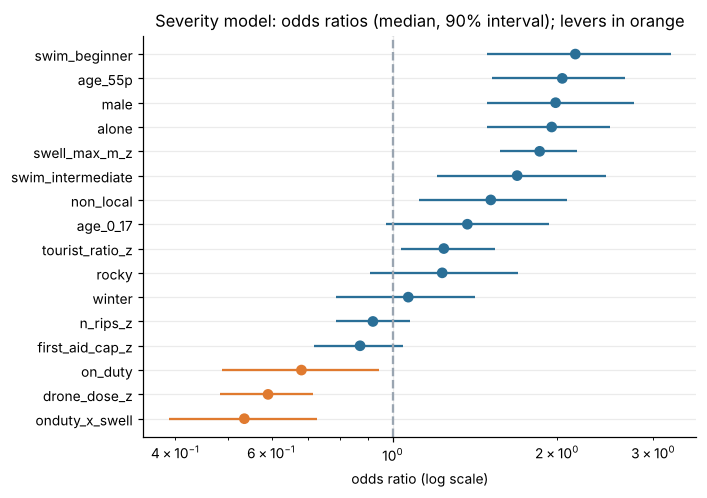

lifeguard-on-duty OR by max swell: {np.float64(1.0): np.float64(0.93), np.float64(1.5): np.float64(0.68), np.float64(2.0): np.float64(0.49), np.float64(2.5): np.float64(0.36), np.float64(3.0): np.float64(0.27)}
drone OR per +100 h/month: 0.21


In [8]:
post_tr = bm.posterior_arrays(idata_tr, n=N_DRAWS, seed=1)
B = post_tr['beta']
sev_or = pd.DataFrame({'OR': np.exp(np.median(B, 0)), 'lo90': np.exp(np.percentile(B, 5, 0)), 'hi90': np.exp(np.percentile(B, 95, 0)),
                       'P(OR<1)': (B < 0).mean(0)}, index=post_tr['x'])
display(sev_or.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4.6))
o = sev_or.sort_values('OR'); y = np.arange(len(o))
col = [ORANGE if i in ('on_duty', 'onduty_x_swell', 'drone_dose_z') else BLUE for i in o.index]
ax.hlines(y, o.lo90, o.hi90, color=col); ax.scatter(o.OR, y, color=col, zorder=3)
ax.axvline(1, color=GREY, ls='--'); ax.set_xscale('log'); ax.set_yticks(y, o.index)
ax.set(title='Severity model: odds ratios (median, 90% interval); levers in orange', xlabel='odds ratio (log scale)')
plt.tight_layout(); plt.show()
sw = np.array([1.0, 1.5, 2.0, 2.5, 3.0]); j1, j2 = post_tr['x'].index('on_duty'), post_tr['x'].index('onduty_x_swell')
eff = np.exp(B[:, [j1]] + B[:, [j2]] * (sw - bf.SWELL_CENTRE))
print('lifeguard-on-duty OR by max swell:', dict(zip(sw, np.median(eff, 0).round(2))))
print('drone OR per +100 h/month:', np.exp(np.median(B[:, post_tr['x'].index('drone_dose_z')]) / SCALER['drone_dose']['sd']).round(2))

In [9]:
p_b = bm.sev_prob(post_tr, Gte).mean(0); y = Gte.sev.values
ml = smf.logit('sev ~ ' + ' + '.join(bm.SEV_X), Gtr).fit(disp=0); p_ml = ml.predict(Gte).values
val = pd.DataFrame({'log-loss': [logloss(np.full_like(p_b, Gtr.sev.mean()), y), logloss(p_ml, y), logloss(p_b, y)],
                    'AUC': [0.5, roc_auc_score(y, p_ml), roc_auc_score(y, p_b)],
                    'predicted severe': [Gtr.sev.mean() * len(y), p_ml.sum(), p_b.sum()], 'observed': y.sum()},
                   index=['constant rate', 'same features, max likelihood', 'Bayesian hierarchical'])
display(val.round(4))
cal = pd.DataFrame({'p': p_b, 'y': y, 'q': pd.qcut(p_b, 5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'])}).groupby('q', observed=True).agg(
    predicted=('p', 'sum'), observed=('y', 'sum'), people=('y', 'size'))
display(cal.round(1))

,log-loss,AUC,predicted severe,observed
constant rate,0.0349,0.5000,52.5327,44
"same features, max likelihood",0.0328,0.7381,36.3225,44
Bayesian hierarchical,0.0328,0.7350,36.5014,44


,predicted,observed,people
q,,,
Q1 lowest,0.9,2,1561
Q2,1.9,1,1560
Q3,3.6,11,1560
Q4,7.2,7,1560
Q5 highest,22.9,23,1561


**Severity: what the model says (training fit)**
- **Who:** the person-level effects are roughly doubling odds each: 55+, male, beginner swimmers, alone, non-local. These are not levers, but they say who campaigns should target.
- **Lifeguards:** being on duty cuts the odds of a severe outcome, and the cut grows with swell. The OR is about 0.9 in 1 m surf, 0.5 in 2 m surf and about 0.35 in 2.5 m surf. **Lifeguard hours are worth most where and when the surf is big.**
- **Drones:** each extra 100 hours a month cuts the odds by about 80% (OR ≈ 0.2).
- **Beach and region effects are small** (SDs ≈ 0.1–0.2 on the log-odds scale) once these are in. The covariates explain the beach differences, so shrinkage of the 30 zero-event beaches is not doing heavy lifting.

**Out of sample:**
- The model beats a constant rate on log-loss and has an AUC of about 0.73. It ties the unpooled fit, so the priors cost nothing in accuracy.
- Calibration by quintile is reasonable.
- It **under-predicts the test total, about 37 against 44.** Section 3 traces where the gap comes from.

## 3. Combined model: expected severe incidents
$$E[\text{severe}_{b,t}] = \underbrace{E[\text{people}_{b,t}]}_{\text{frequency}} \times \underbrace{\frac{1}{n_{b,s}}\sum_{i \in \text{template}(b,s)} \Big[c_{b,t}\,\Pr(\text{sev}_i \mid \text{on}) + (1-c_{b,t})\,\Pr(\text{sev}_i \mid \text{off})\Big]}_{\text{severity}}$$

- The person mix (age, sex, swim level, alone, local) is the training people observed at that beach in that season. Cells with fewer than 40 people fall back to region × season.
- $c_{b,t}$ is `coverage_hat`, the chance a lifeguard is on duty at an incident given the hours funded. This is the term through which extra lifeguard hours lower severity.
- Uncertainty: frequency coefficients are drawn from their sampling distribution, paired with severity posterior draws.

**Benchmark:** a direct Poisson model of `n_severe` per beach-month (region, season, conditions, levers), plus a naive region × season rate. If the decomposition is worth its complexity, it should beat both on held-out seasons.

In [10]:
T_tr = bm.person_templates(Gtr, POSTCODES)
fd_tr = bm.freq_param_draws(freq_tr, N_DRAWS, seed=2)
E_te = bm.expected_severe(te, freq_tr, fd_tr, post_tr, T_tr)
direct_f = 'n_severe ~ C(region) + winter + swell_max_m_z + rocky + n_rips_z + tourist_ratio_z + coverage_hat_z + drone_dose_z + campaign_sqrt'
direct = smf.glm(direct_f, tr, family=sm.families.Poisson(), offset=tr.log_visitors).fit()
rate = tr.groupby(['region', 'winter']).apply(lambda g: g.n_severe.sum() / g.visitors.sum(), include_groups=False).rename('rate')
bt = te[['beach_nm', 'fy', 'winter', 'drone_on', 'n_severe']].assign(
    naive=te.join(rate, on=['region', 'winter']).eval('rate * visitors').values,
    direct=direct.predict(te, offset=te.log_visitors).values,
    combined=E_te.mean(0))
score = pd.DataFrame({k: {'test Poisson log score': stats.poisson.logpmf(bt.n_severe, bt[k]).sum(),
                          'predicted total': bt[k].sum(),
                          'beach-level corr': np.corrcoef(bt.groupby('beach_nm')[k].sum(), bt.groupby('beach_nm').n_severe.sum())[0, 1]}
                      for k in ['naive', 'direct', 'combined']}).T.assign(observed=bt.n_severe.sum())
display(score.round(3))
tot = E_te.sum(1)
print(f'combined total, 90% interval: {np.percentile(tot, 5):.1f}–{np.percentile(tot, 95):.1f} (parameter uncertainty only); '
      f'P(Poisson total ≥ 44 | mean {tot.mean():.1f}) = {stats.poisson.sf(43, tot.mean()):.3f}')
display(bt.assign(drone_beach=bt.groupby('beach_nm').drone_on.transform('max'))
          .groupby(['fy', 'winter']).agg(observed=('n_severe', 'sum'), combined=('combined', 'sum'), direct=('direct', 'sum')).round(1))

,test Poisson log score,predicted total,beach-level corr,observed
naive,-194.670,51.091,0.448,44
direct,-188.425,40.123,0.652,44
combined,-184.169,37.328,0.719,44


combined total, 90% interval: 31.3–44.1 (parameter uncertainty only); P(Poisson total ≥ 44 | mean 37.3) = 0.156


observed  combined  direct
fy   winter                            
2025 0             13       8.7     9.2
     1              5       9.2    10.1
2026 0             14       9.4    10.0
     1             12      10.0    10.8

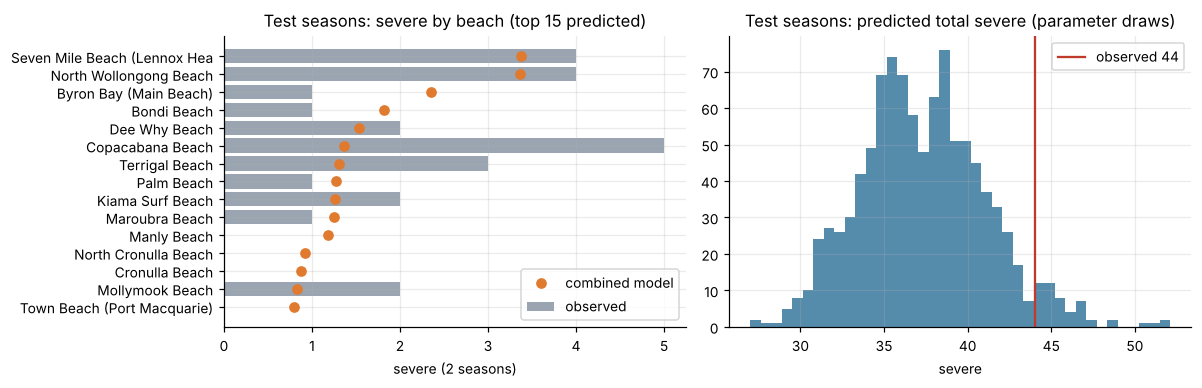

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
bb = bt.groupby('beach_nm')[['n_severe', 'combined', 'direct']].sum().sort_values('combined', ascending=False)
top = bb.head(15)[::-1]; yy = np.arange(len(top))
ax[0].barh(yy, top.n_severe, color=GREY, label='observed'); ax[0].plot(top.combined, yy, 'o', color=ORANGE, label='combined model')
ax[0].set_yticks(yy, [n[:28] for n in top.index]); ax[0].set(title='Test seasons: severe by beach (top 15 predicted)', xlabel='severe (2 seasons)'); ax[0].legend()
ax[1].hist(tot, bins=40, color=BLUE, alpha=.8); ax[1].axvline(bt.n_severe.sum(), color=RED, label='observed 44')
ax[1].set(title='Test seasons: predicted total severe (parameter draws)', xlabel='severe'); ax[1].legend()
plt.tight_layout(); plt.show()

**Combined model: verdict**
- The frequency × severity model **beats both benchmarks** on held-out log score and on beach ranking. Splitting the problem is worth the complexity.
- It does **under-predict the total** (≈37 against 44, Poisson p ≈ 0.16). The gap is entirely **Sep–Apr** (about 18 predicted against 27 observed over the two seasons). Winter is about right (19 against 17). Frequency is right in both, so severe outcomes ran high in summer.
  - The summer shortfall sits mostly at **beaches without drones**, so it is not the drone effect over-promising.
  - Read it as noise, or a summer level shift the model does not catch. The refit below includes both test seasons, which pulls the level up (next-year baseline ≈ 20.5 against an observed 10-season mean of 22).
- **For the panel:** the uncertainty bands above cover parameter uncertainty only. Next year's actual count will scatter around the forecast with roughly Poisson noise on top (±√20 ≈ ±4–5).

## 4. Refit on all ten seasons
The same specifications, refitted on all data, including the coverage model. These are the models the allocation uses.

In [12]:
cov_all = bm.fit_coverage(Q_raw, test_from_fy=9999)
Fa, Ga = build_tables(cov_all)
Fa = bm.add_model_terms(bf.apply_scaler(Fa, SCALER), POSTCODES)      # scaler stays the train one: only a centring choice
Ga = bm.add_model_terms(bf.apply_scaler(Ga, SCALER), POSTCODES)
freq_all = bm.fit_frequency(Fa)
t0 = time.time()
with bm.build_severity_model(Ga, beaches, regions, beach_region):
    idata_all = pm.sample(random_seed=12, **SAMPLE_KW)
s_all = az.summary(idata_all, var_names=['a', 'beta', 's_region', 's_beach'])
print(f"sampled in {time.time() - t0:.0f}s; divergences {int(idata_all.sample_stats['diverging'].sum())}; "
      f"max r_hat {s_all.r_hat.max():.3f}; min bulk ESS {s_all.ess_bulk.min():.0f}")
post_all = bm.posterior_arrays(idata_all, n=N_DRAWS, seed=3)
fd_all = bm.freq_param_draws(freq_all, N_DRAWS, seed=4)
T_all = bm.person_templates(Ga, POSTCODES)
keep = [p for p in freq_all.params.index if not p.startswith('C(') and p not in ('Intercept', 'alpha')]
cmp = pd.concat({'freq IRR (train)': np.exp(freq_tr.params[keep]), 'freq IRR (all)': np.exp(freq_all.params[keep])}, axis=1)
display(cmp.round(3))
display(pd.DataFrame({'sev OR (train)': np.exp(np.median(post_tr['beta'], 0)), 'sev OR (all)': np.exp(np.median(post_all['beta'], 0))},
                     index=post_all['x']).round(3))

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [a, beta, s_region, z_r, s_beach, z_b]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 630 seconds.


There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


sampled in 633s; divergences 2; max r_hat 1.003; min bulk ESS 1551


,freq IRR (train),freq IRR (all)
t_years_z,1.000,0.999
swell_max_m_z,1.034,1.036
water_temp_z,1.003,1.037
rain_mm_z,1.021,1.020
wind_days_z,1.022,1.024
tourist_ratio_z,1.189,1.180
surfer_prop_z,0.969,0.964
coverage_hat_z,0.973,0.972
drone_dose_z,0.989,0.986
campaign_sqrt,0.475,0.471


,sev OR (train),sev OR (all)
age_0_17,1.370,1.589
age_55p,2.045,2.070
male,1.988,2.077
swim_beginner,2.161,2.123
swim_intermediate,1.691,1.593
non_local,1.513,1.591
alone,1.956,1.829
on_duty,0.681,0.655
onduty_x_swell,0.535,0.566
drone_dose_z,0.591,0.628


## 5. What each lever buys, by beach
**The next-year baseline** is 2025–26 conditions rolled forward one year: same visitors, weather and levers, with the trend term advanced.

Each lever gets **+1,000 hours a year** (or one campaign step) at each beach separately, and the change in expected severe incidents is recorded, with uncertainty. Equal units make the levers comparable once the unit costs are in.

| Scenario | Change to the panel |
|---|---|
| Lifeguards, winter | +250 h/month, May–Aug |
| Lifeguards, Sep–Apr | +125 h/month, Sep–Apr |
| Drones, winter | +250 h/month, May–Aug (**outside observed data**: winter max 15 h) |
| Drones, Sep–Apr | +125 h/month, Sep–Apr (capped at 150 h/month, the observed max) |
| Campaign | +0.25 intensity in Nov–Feb (capped at 1) |

These are **one-at-a-time marginal effects**. The models have diminishing returns built in (coverage saturates, campaigns are concave, probabilities are bounded), so the allocation should re-evaluate after each block of funding rather than multiply these numbers up.

In [13]:
yr = P_raw.month.str[-4:].astype(int); mo_ = P_raw.month.str[:2].astype(int)
BASE = P_raw[(yr * 100 + mo_) >= 202509].copy()
BASE['month'] = BASE.month.str[:3] + (BASE.month.str[-4:].astype(int) + 1).astype(str)
bmo = BASE.month.str[:2].astype(int)
WIN, SUM, CMP = bmo.isin(bf.WINTER), ~bmo.isin(bf.WINTER), bmo.isin(bm.CAMPAIGN_MONTHS)

def by_beach(P_scn):
    Fs = bm.scenario_features(P_scn, cov_all, SCALER, POSTCODES)
    E = bm.expected_severe(Fs, freq_all, fd_all, post_all, T_all)
    return pd.DataFrame(E.T, index=Fs.beach_nm.values).groupby(level=0).sum()      # beach x draws

def bump(col, amt, mask, cap=None):
    X = BASE.copy(); X.loc[mask, col] += amt
    if cap is not None: X[col] = X[col].clip(upper=cap)
    return X

base = by_beach(BASE)
print(f'next-year baseline: {base.sum().mean():.1f} expected severe (90%: {np.percentile(base.sum(), 5):.1f}–{np.percentile(base.sum(), 95):.1f}); '
      f'last season observed {int(F[F.fy == 2026].n_severe.sum())}, 10-season mean {F.groupby("fy").n_severe.sum().mean():.1f}')
SCN = {'lg_winter': bump('lg_hrs', 250, WIN), 'lg_sepapr': bump('lg_hrs', 125, SUM),
       'drone_winter': bump('drone_hrs', 250, WIN), 'drone_sepapr': bump('drone_hrs', 125, SUM, cap=bm.DRONE_MAX),
       'campaign': bump('campaign_idx', 0.25, CMP, cap=1.0)}
display(pd.DataFrame({k: bm.support_check(v) for k, v in SCN.items()}).T)
D = {k: base - by_beach(v) for k, v in SCN.items()}                    # averted severe, beach x draws

next-year baseline: 20.5 expected severe (90%: 17.8–23.3); last season observed 26, 10-season mean 22.0


,drone_hrs_above_max,winter_drone_above_15h,campaign_outside_nov_feb,lg_hrs_above_3500
lg_winter,0,0,0,0
lg_sepapr,0,0,0,0
drone_winter,320,320,0,0
drone_sepapr,0,0,0,0
campaign,0,0,0,0


In [14]:
units = {'lg_winter': 1000, 'lg_sepapr': 1000, 'drone_winter': 1000,
         'drone_sepapr': (SCN['drone_sepapr'].drone_hrs - BASE.drone_hrs).groupby(BASE.beach_nm).sum(), 'campaign': 1}
eff = []
for k, d in D.items():
    u = units[k]
    per = d.div(u, axis=0) * (1000 if k.startswith(('lg', 'drone')) else 1)   # per 1,000 h actually added (cap-aware)
    eff.append(pd.DataFrame({'lever': k, 'beach_nm': d.index, 'averted_mean': per.mean(axis=1).values,
                             'averted_p10': per.quantile(.1, axis=1).values, 'averted_p90': per.quantile(.9, axis=1).values,
                             'P(averts>0)': (d > 0).mean(axis=1).values}))
eff = pd.concat(eff, ignore_index=True).replace([np.inf, -np.inf], np.nan)
ctx = pd.DataFrame({'baseline_severe': base.mean(axis=1),
                    'region': pd.Series(POSTCODES).map(bm.region_of),
                    'lg_hrs_winter': BASE[WIN].groupby('beach_nm').lg_hrs.sum(), 'lg_hrs_sepapr': BASE[SUM].groupby('beach_nm').lg_hrs.sum(),
                    'drone_hrs_yr': BASE.groupby('beach_nm').drone_hrs.sum(), 'campaign_nov_feb': BASE[CMP].groupby('beach_nm').campaign_idx.mean()})
wide = eff.pivot(index='beach_nm', columns='lever', values='averted_mean')[list(SCN)].join(ctx)
summary = pd.DataFrame({k: {'all 80 beaches (sum)': D[k].sum().mean(), 'best beach': D[k].mean(axis=1).max(),
                            'best beach name': D[k].mean(axis=1).idxmax(), 'median beach': D[k].mean(axis=1).median()} for k in SCN}).T
print('Severe incidents averted per year for each scenario step in the table above (drones Sep–Apr: fewer hours where the 150 h cap binds):')
display(summary)
wide.sort_values('baseline_severe', ascending=False).head(20).round(3)

Severe incidents averted per year for each scenario step in the table above (drones Sep–Apr: fewer hours where the 150 h cap binds):


,all 80 beaches (sum),best beach,best beach name,median beach
lg_winter,1.5326,0.328503,Seven Mile Beach (Lennox Head),0.00805
lg_sepapr,0.453139,0.109359,Seven Mile Beach (Lennox Head),0.001419
drone_winter,9.507926,1.238602,Seven Mile Beach (Lennox Head),0.046674
drone_sepapr,7.197652,1.036725,North Wollongong Beach,0.03638
campaign,1.029151,0.105198,Copacabana Beach,0.004488


,lg_winter,lg_sepapr,drone_winter,drone_sepapr,campaign,baseline_severe,region,lg_hrs_winter,lg_hrs_sepapr,drone_hrs_yr,campaign_nov_feb
beach_nm,,,,,,,,,,,
Seven Mile Beach (Lennox Head),0.329,0.109,1.239,0.904,0.042,2.085,North Coast,0.0,3128.6,736.7,0.385
North Wollongong Beach,0.026,0.011,0.463,1.037,0.023,1.743,Illawarra,2884.7,15801.4,0.0,0.862
Byron Bay (Main Beach),0.061,0.016,0.668,0.613,0.032,1.256,North Coast,3108.6,16504.0,658.4,0.314
Bondi Beach,0.020,0.002,0.460,0.627,0.034,0.999,Sydney,3567.8,19447.2,803.9,0.326
Copacabana Beach,0.061,0.038,0.308,0.555,0.105,0.995,Central Coast & Hunter,0.0,2926.5,0.0,0.000
Terrigal Beach,0.012,0.001,0.338,0.598,0.098,0.891,Central Coast & Hunter,2715.6,17002.1,687.4,0.000
Dee Why Beach,0.025,0.001,0.478,0.516,0.020,0.822,Sydney,2838.8,17379.8,1089.8,0.418
Kiama Surf Beach,0.047,0.043,0.214,0.411,0.080,0.723,Illawarra,0.0,2771.9,0.0,0.000
Maroubra Beach,0.005,0.002,0.223,0.501,0.079,0.690,Sydney,2733.4,18065.8,673.7,0.000


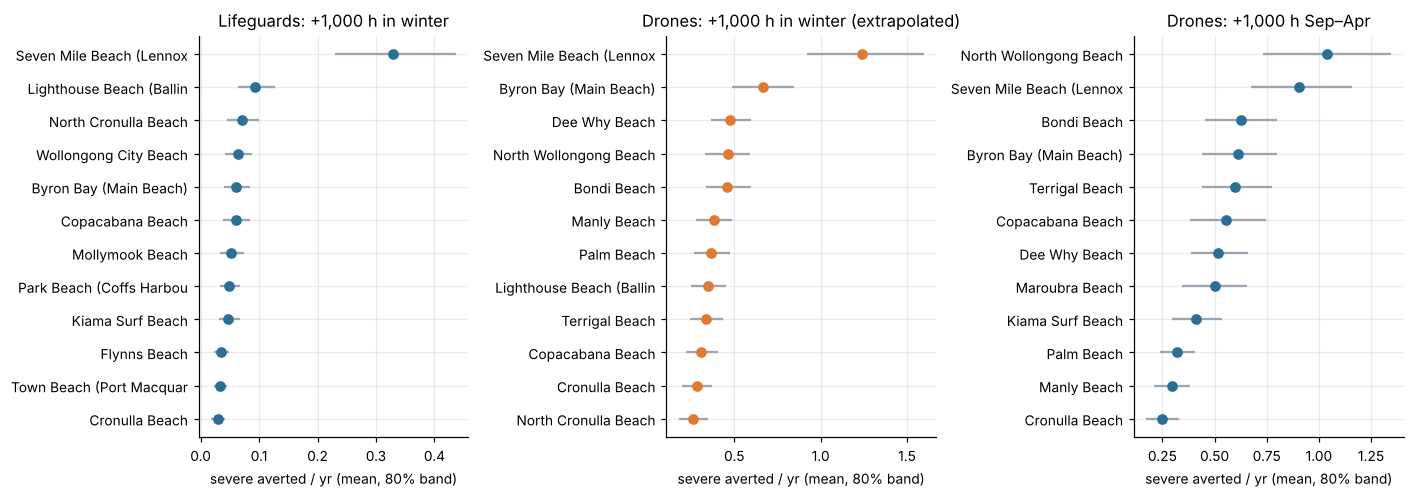

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), sharey=False)
for ax, k, title in zip(axs, ['lg_winter', 'drone_winter', 'drone_sepapr'],
                        ['Lifeguards: +1,000 h in winter', 'Drones: +1,000 h in winter (extrapolated)', 'Drones: +1,000 h Sep–Apr']):
    e = eff[eff.lever == k].nlargest(12, 'averted_mean')[::-1]; yy = np.arange(len(e))
    ax.hlines(yy, e.averted_p10, e.averted_p90, color=GREY); ax.plot(e.averted_mean, yy, 'o', color=ORANGE if 'winter' in k and 'drone' in k else BLUE)
    ax.set_yticks(yy, [n[:24] for n in e.beach_nm]); ax.set(title=title, xlabel='severe averted / yr (mean, 80% band)')
plt.tight_layout(); plt.show()

**Lever effects: reading them**
- **One beach dominates every lever: Seven Mile Beach (Lennox Head).** It has about 10% of next year's expected severe incidents, a seasonal patrol and low winter drone hours. Any allocation starts there.
- **Lifeguard hours are worth over 3× more in winter than in Sep–Apr.** In summer, coverage is already near saturation at most beaches. In winter most beaches have none, and the surf is bigger, which is exactly where the on-duty effect is largest.
- **Drone hours have the largest effect per hour in the data.** But the winter numbers rest on an assumption the data cannot test: that a winter drone hour works like a summer one. Present it as the upside case, alongside a sensitivity run (for example, halving the winter drone effect).
- **Campaigns avert little severe harm** (≈1.0 a year summed over all 80 beaches for +0.25). They run in summer, when severity is lowest, and do not change severity. They cut mild incidents a lot, which matters for workload but not for this objective.
- **Next step: costs.** `beach_allocation.ipynb` prices these effects with `pricing.csv` and allocates the $2M.

**Caveats to carry into the deck**
1. Lifeguard effects on severity come from the on-duty/off-duty contrast *within* patrolled beach-months, which is partly a time-of-day contrast (early morning, evening). Some of the effect may be dusk or fewer bystanders rather than lifeguards. Treat it as an upper bound.
2. The drone effect comes from the staggered rollout (35 beaches in four cohorts) together with a summer/winter dose contrast. Its strength is that it holds out of sample at drone beaches. Its weakness is that it cannot separate "winter hours are few" from "winter conditions blunt drones".
3. Infrastructure (flags, PA, equipment) cannot be estimated from these data: there is too little within-beach variation, as the EDA found. Say so rather than allocate to it on a guess.

In [16]:
pd.Series(freq_all.params).to_csv(OUT + 'freq_params.csv')
freq_all.cov_params().to_csv(OUT + 'freq_cov.csv')
bm.save_posterior(post_all, OUT + 'sev_posterior.npz')
eff.to_csv(OUT + 'lever_effects_long.csv', index=False)
wide.to_csv(OUT + 'lever_effects_by_beach.csv')
bt.to_csv(OUT + 'backtest_test_seasons.csv', index=False)
with open(OUT + 'scaler.json', 'w') as f: json.dump(SCALER, f, indent=2)
print(sorted(os.listdir(OUT)))

['backtest_test_seasons.csv', 'freq_cov.csv', 'freq_params.csv', 'lever_effects_by_beach.csv', 'lever_effects_long.csv', 'scaler.json', 'sev_posterior.npz']


## 6. Using this in the allocation notebook
```python
import beach_features as bf, beach_models as bm
# refit (seconds for frequency; load the severity posterior rather than resampling)
cov_all  = bm.fit_coverage(Q_raw, test_from_fy=9999)
post_all = bm.load_posterior('models/sev_posterior.npz')
# P_scn = next-year baseline panel with funded hours / campaign changes applied
Fs = bm.scenario_features(P_scn, cov_all, SCALER, POSTCODES)
E  = bm.expected_severe(Fs, freq_all, fd_all, post_all, T_all)     # draws x beach-months
bm.support_check(P_scn)                                             # flag extrapolated lever values
```
`beach_allocation.ipynb` does this: it optimises expected severe averted per dollar greedily in blocks (for example $50k), re-evaluating after each block so diminishing returns are respected. Report the 80% band of the total from the draws.